# Spectral-based audio features with Essentia

In this notebook we explain, compute, listen to, and visualize *single-frame* descriptors:

1. **Energy, RMS, and Loudness** — amplitude and a simple loudness approximation.
2. **Spectral centroid** — the spectral center of mass, related to brightness.
3. **MFCCs** — a compact representation of spectral shape using mel bands and a cosine transform.
4. **Pitch salience function** — how well candidate fundamental frequencies are supported by spectral harmonics.
5. **HPCP (chroma)** — how the energy of spectral peaks is distributed among pitch classes.

Finally, we examine feature trajectories, an interactive frame inspector, and statistics over time.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display

try:
    import essentia
    import essentia.standard as es
except ImportError as exc:
    raise ImportError(
        "Essentia is required. Install with: %pip install essentia  "
        "(or use the environment configured for sms-tools-materials)."
    ) from exc

SR = 44100
FRAME_SIZE = 4096
HOP_SIZE = 1024
EPS = 1e-12

plt.rcParams.update({'figure.figsize': (11, 3.7), 'axes.grid': True, 'grid.alpha': 0.22})
print('Essentia version:', getattr(essentia, '__version__', 'unknown'))
print(f'Sample rate: {SR} Hz | frame: {FRAME_SIZE} samples | hop: {HOP_SIZE} samples')

Essentia version: 2.1-beta6-dev
Sample rate: 44100 Hz | frame: 4096 samples | hop: 1024 samples


## 1. Choose a sound and examine its spectrum

### A controlled listening example

We synthesize five successive regions so that the descriptors have different behaviors:

- **A2, mellow**: 110 Hz with relatively weak upper harmonics.
- **A3, bright**: 220 Hz with relatively strong upper harmonics. This has the *same pitch class* as A2, one octave higher.
- **C-major chord**: simultaneous C4, E4, G4 harmonic tones.
- **Silence**: a region with (approximately) zero energy.
- **Noise**: a broadband, unpitched signal.

The comparison is deliberately controlled: in natural recordings, amplitude, timbre, pitch, articulation, and background noise all change together. Harmonic strengths and waveform amplitude are not meant to model calibrated physical loudness.

The same analysis can be applied to a real recording by setting `AUDIO_PATH` to a file, for example `"../sounds/your_sound.wav"`. Essentia's `MonoLoader` will downmix and resample the file; its availability for compressed formats depends on the installed audio backend.

Synthesized classroom demonstration: 6.25 s, 44100 Hz, mono


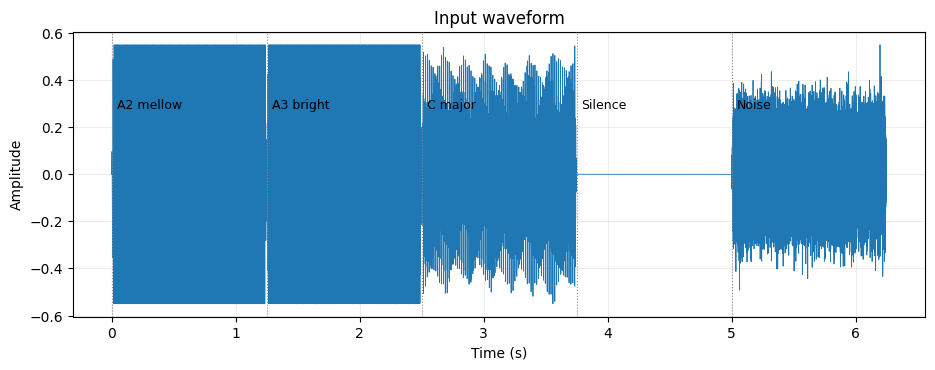

In [2]:
# For your own sound, use a path such as '../sounds/your_sound.wav'.
AUDIO_PATH = None
MAX_SECONDS = 15  # Limit lengthy tracks for convenient classroom execution.

def harmonic_tone(f0, duration, amplitudes, sr=SR):
    t = np.arange(round(duration * sr), dtype=np.float64) / sr
    y = np.zeros_like(t)
    for k, amplitude in enumerate(amplitudes, 1):
        y += amplitude * np.sin(2 * np.pi * f0 * k * t)
    y /= max(np.max(np.abs(y)), EPS)
    fade = min(round(0.012 * sr), len(y) // 2)
    y[:fade] *= np.linspace(0, 1, fade)
    y[-fade:] *= np.linspace(1, 0, fade)
    return y


def demo_audio(sr=SR):
    duration = 1.25
    dark = harmonic_tone(110, duration, 1 / np.arange(1, 10)**2.0, sr) * 0.55
    bright = harmonic_tone(220, duration, 1 / np.arange(1, 13)**0.75, sr) * 0.55
    notes = [261.6256, 329.6276, 391.9954]  # C4, E4, G4
    chord = sum(harmonic_tone(f, duration, 1 / np.arange(1, 8)**1.2, sr) for f in notes)
    chord = chord / max(np.max(np.abs(chord)), EPS) * 0.55
    silence = np.zeros(round(duration * sr))
    rng = np.random.default_rng(22)
    noise = rng.normal(size=round(duration * sr))
    noise = noise / max(np.max(np.abs(noise)), EPS) * 0.55
    fade = min(round(0.012 * sr), len(noise) // 2)
    noise[:fade] *= np.linspace(0, 1, fade)
    noise[-fade:] *= np.linspace(1, 0, fade)

    names = ['A2 mellow', 'A3 bright', 'C major', 'Silence', 'Noise']
    segments = [dark, bright, chord, silence, noise]
    starts = np.cumsum([0] + [len(s) / sr for s in segments[:-1]]).tolist()
    return np.concatenate(segments).astype(np.float32), list(zip(names, starts, [duration] * 5))

if AUDIO_PATH is None:
    audio, regions = demo_audio()
    audio_label = 'Synthesized classroom demonstration'
else:
    path = Path(AUDIO_PATH).expanduser()
    if not path.is_file():
        raise FileNotFoundError(f'Audio file not found: {path.resolve()}')
    audio = es.MonoLoader(filename=str(path.resolve()), sampleRate=SR)()
    audio = np.asarray(audio[:round(MAX_SECONDS * SR)], dtype=np.float32)
    regions = []
    audio_label = path.name

if len(audio) < FRAME_SIZE:
    raise ValueError(f'At least {FRAME_SIZE} samples are needed for this analysis.')

print(f'{audio_label}: {len(audio)/SR:.2f} s, {SR} Hz, mono')
display(Audio(audio, rate=SR, normalize=False))

time_audio = np.arange(len(audio)) / SR
fig, ax = plt.subplots()
ax.plot(time_audio, audio, lw=0.6)
for name, start, dur in regions:
    ax.axvline(start, color='0.55', ls=':', lw=0.8)
    ax.text(start + 0.04, 0.73, name, transform=ax.get_xaxis_transform(), fontsize=9)
ax.set(xlabel='Time (s)', ylabel='Amplitude', title='Input waveform')
plt.show()

### From a short-time frame to a magnitude spectrum

In the slides (slide 3), features are extracted from a **windowed frame** of the sound:

$$
x_m[n] = x[n+mH],\quad x_{w,m}[n]=w[n]x_m[n],\quad
X_m[k]=\sum_{n=0}^{N-1} x_{w,m}[n]e^{-j2\pi kn/N}.
$$

Here, $N$ is the frame length, $H$ is the hop size, and $w[n]$ is the analysis window. Essentia's `Spectrum` returns the **linear magnitude** $S_m[k]=|X_m[k]|$. To compute the frequency axis, use $f_k=k f_s/N$.

Windowing mainly reduces spectral leakage. The resulting magnitude and the extracted peaks depend on the window type and FFT size. The spectral descriptors below are based on the same windowed spectrum for a meaningful comparison.

Frames: (266, 4096) | Spectra: (266, 2049)


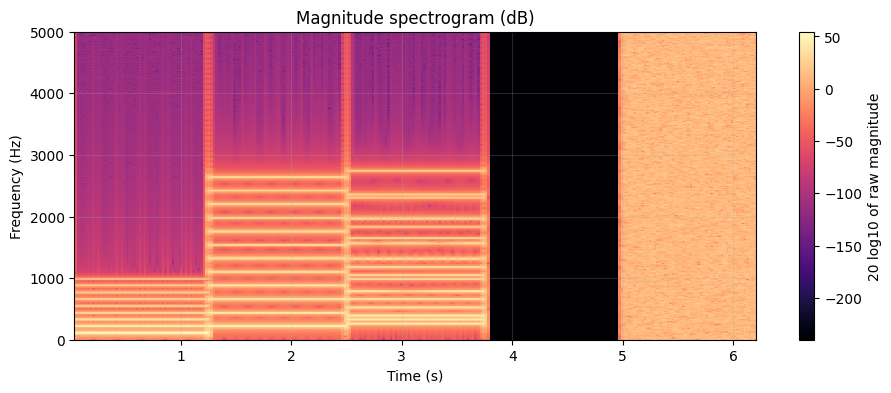

In [3]:
# Use only complete frames so their locations and lengths are unambiguous.
frames = list(es.FrameGenerator(audio, frameSize=FRAME_SIZE, hopSize=HOP_SIZE,
                                startFromZero=True, validFrameThresholdRatio=1))
frames = np.asarray(frames, dtype=np.float32)
frame_times = (np.arange(len(frames)) * HOP_SIZE + FRAME_SIZE / 2) / SR

window = es.Windowing(type='hann', size=FRAME_SIZE,
                      normalized=False, zeroPhase=False)
spectrum_alg = es.Spectrum(size=FRAME_SIZE)
spectra = np.asarray([spectrum_alg(window(frame)) for frame in frames])
freq_axis = np.fft.rfftfreq(FRAME_SIZE, d=1/SR)

print('Frames:', frames.shape, '| Spectra:', spectra.shape)
fig, ax = plt.subplots(figsize=(11, 4))
im = ax.pcolormesh(frame_times, freq_axis, 20*np.log10(np.maximum(spectra, EPS)).T,
                   shading='auto', cmap='magma')
ax.set(ylim=(0, 5000), xlabel='Time (s)', ylabel='Frequency (Hz)', title='Magnitude spectrogram (dB)')
fig.colorbar(im, ax=ax, label='20 log10 of raw magnitude')
plt.show()

## 2. Energy, RMS, and Loudness

These three descriptors are related to **signal amplitude**, but are not interchangeable.

For an *unwindowed* frame $x[n]$ of $N$ samples, its discrete-time energy is

$$
E = \sum_{n=0}^{N-1}x^2[n].
$$

The **root mean square (RMS)** is the square root of the *average* squared amplitude:

$$
\operatorname{RMS}=\sqrt{\frac{1}{N}\sum_{n=0}^{N-1}x^2[n]}
=\sqrt{\frac{E}{N}}.
$$

For the non-normalized discrete Fourier transform, **Parseval's theorem** gives

$$
\sum_n x^2[n] = \frac{1}{N}\sum_{k=0}^{N-1}|X[k]|^2.
$$

This lets us compute energy in the spectral domain, **provided** we use the *same input samples* (windowed or unwindowed) and consistent FFT normalization. Energy depends on frame length; RMS is usually more convenient for comparing equal-amplitude recordings at different frame sizes.

**Loudness** aims to approximate perceived intensity, which is more complicated than amplitude. Essentia's simple `Loudness` algorithm follows a form of **Stevens' power law**:

$$
L_{\mathrm{Essentia}}= E^{0.67}.
$$

It is useful for teaching, but **not** a calibrated loudness value in LUFS, phon, or sone; it does *not* implement perceptual frequency weighting or the EBU R128 standard. The amplitude of our synthesized audio is not calibrated to sound pressure level. Real-world loudness normalization is better studied with a separate algorithm such as `LoudnessEBUR128`.

**Essentia:** [`Energy`](https://essentia.upf.edu/reference/std_Energy.html), [`RMS`](https://essentia.upf.edu/reference/std_RMS.html), [`Loudness`](https://essentia.upf.edu/reference/std_Loudness.html).

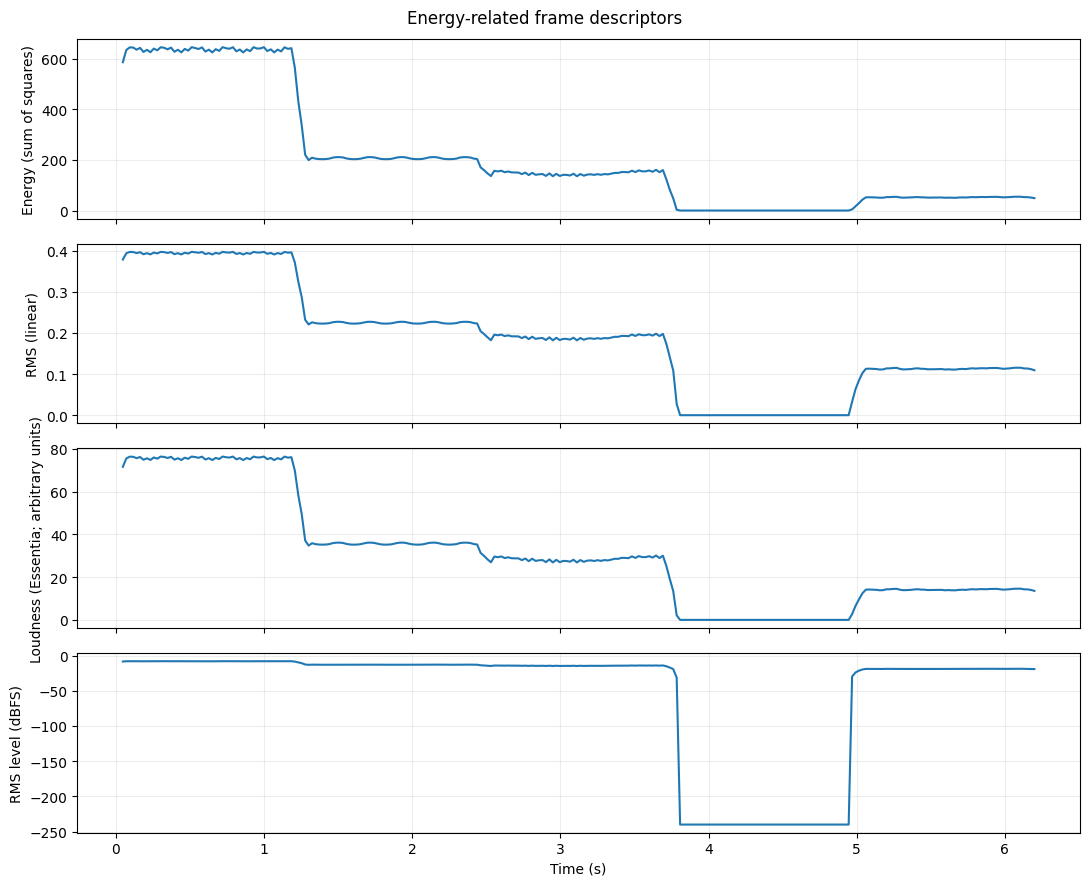

Frame 88: Energy from Essentia = 206.83, from DFT = 206.83


In [4]:
energy_alg, rms_alg, loudness_alg = es.Energy(), es.RMS(), es.Loudness()
energy = np.asarray([energy_alg(frame) for frame in frames])
rms = np.asarray([rms_alg(frame) for frame in frames])
loudness = np.asarray([loudness_alg(frame) for frame in frames])
rms_dbfs = 20 * np.log10(np.maximum(rms, EPS))  # Relative digital signal level, not dB SPL.

# A direct mathematical check of the frame-level relation.
assert np.allclose(energy, FRAME_SIZE * rms**2, rtol=2e-4, atol=1e-6)

fig, axes = plt.subplots(4, 1, figsize=(11, 9), sharex=True)
for ax, values, label in zip(axes,
    [energy, rms, loudness, rms_dbfs],
    ['Energy (sum of squares)', 'RMS (linear)', 'Loudness (Essentia; arbitrary units)', 'RMS level (dBFS)']):
    ax.plot(frame_times, values, lw=1.5)
    ax.set(ylabel=label)
axes[-1].set(xlabel='Time (s)')
fig.suptitle('Energy-related frame descriptors')
plt.tight_layout()
plt.show()

# Verify Parseval for one *unwindowed* frame, using the full complex FFT.
i = len(frames) // 3
energy_from_fft = np.sum(np.abs(np.fft.fft(frames[i]))**2) / FRAME_SIZE
print(f'Frame {i}: Energy from Essentia = {energy[i]:.5g}, from DFT = {energy_from_fft:.5g}')

## 3. Spectral centroid

The spectral centroid is the **center of mass of the magnitude spectrum**. With $S[k]=|X[k]|$ and bin-center frequencies $f_k$,

$$
C=\frac{\sum_{k=0}^{N/2}f_k S[k]}{\sum_{k=0}^{N/2}S[k]}\quad\text{(Hz)}.
$$

Larger values typically correspond to more high-frequency energy, which is often perceived as greater **brightness**. The centroid is *not* a pitch estimate: a noisy sound may have a high centroid but no musical pitch.

Essentia's general `Centroid` algorithm expects an array of weights (the spectrum here) and a `range` parameter. For spectral centroid in **Hz**, set `range = sampleRate/2`. This follows the documented Essentia convention. We use the magnitude spectrum, not the power spectrum, in order to match the lecture definition.

**Essentia:** [`Centroid`](https://essentia.upf.edu/reference/std_Centroid.html).

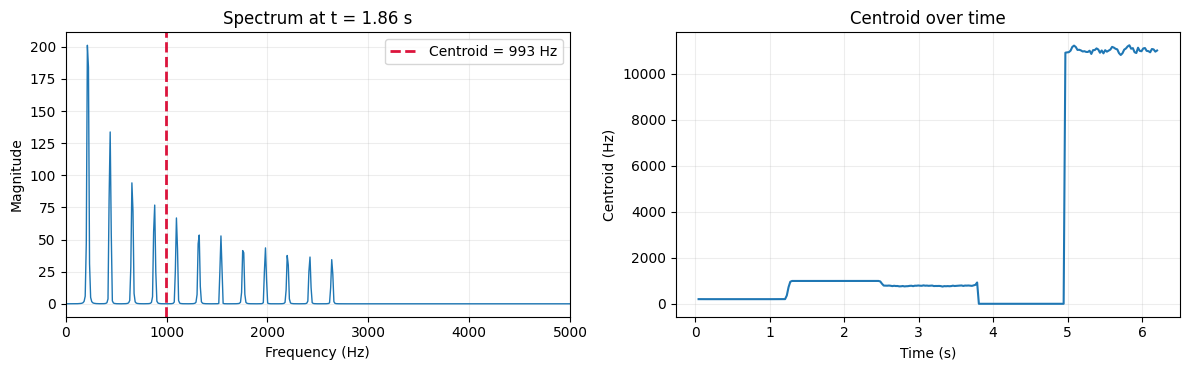

Essentia: 993.47 Hz | formula: 993.48 Hz


In [5]:
centroid_alg = es.Centroid(range=SR / 2)
centroid = np.asarray([centroid_alg(s) if np.sum(s) > EPS else 0.0 for s in spectra])

# Inspect a frame in the bright harmonic segment (or at 1/3 of an uploaded audio).
INSPECT_TIME = 1.85 if regions else len(audio) / SR / 3
inspect_idx = int(np.argmin(np.abs(frame_times - INSPECT_TIME)))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(freq_axis, spectra[inspect_idx], lw=1)
axes[0].axvline(centroid[inspect_idx], color='crimson', ls='--', lw=2,
                label=f'Centroid = {centroid[inspect_idx]:.0f} Hz')
axes[0].set(xlim=(0, 5000), xlabel='Frequency (Hz)', ylabel='Magnitude',
            title=f'Spectrum at t = {frame_times[inspect_idx]:.2f} s')
axes[0].legend()
axes[1].plot(frame_times, centroid, lw=1.5)
axes[1].set(xlabel='Time (s)', ylabel='Centroid (Hz)', title='Centroid over time')
plt.tight_layout()
plt.show()

# Compare with the explicit weighted-mean equation.
s = spectra[inspect_idx]
centroid_formula = np.sum(freq_axis * s) / max(np.sum(s), EPS)
print(f'Essentia: {centroid[inspect_idx]:.2f} Hz | formula: {centroid_formula:.2f} Hz')

### Spectral roll-off and flatness

Roll-off is the lowest frequency bin at which cumulative spectral power reaches 85% of the total. Compare it with the magnitude-weighted centroid on the same frame. Flatness is the geometric mean of bin power divided by its arithmetic mean. It approaches 1 for equal power across bins and is smaller when power is concentrated in a few bins. The calculation floors relative bin power at 1e-12 before taking logs. Both descriptors are undefined for silent frames.

For the demo, compare the sustained notes and noise. With a recording, look for a sustained note, an attack, or a breath and see which region has the highest flatness. Then change the inspection time above to see its spectrum.

The lower panel shows one flatness measurement per frame. Higher values indicate more evenly distributed spectral power. Lower values indicate stronger peaks. The gap during silence means flatness is undefined. The dot and dashed line link the selected time to the spectrum above.

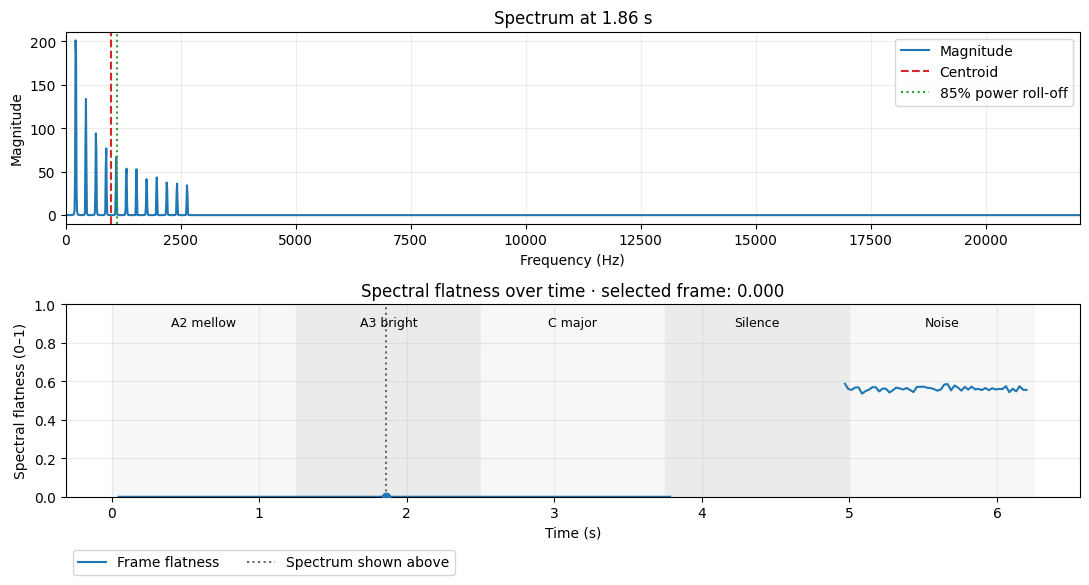

In [31]:
power = spectra.astype(np.float64)**2
cumulative_power = np.cumsum(power, axis=1)
total_power = cumulative_power[:, -1]
has_power = total_power > 0
rolloff = np.full(len(spectra), np.nan)
flatness = np.full(len(spectra), np.nan)

rolloff_bins = np.argmax(
    cumulative_power[has_power] >= 0.85 * total_power[has_power, None], axis=1
)
rolloff[has_power] = freq_axis[rolloff_bins]
relative_power = power[has_power] / power[has_power].max(axis=1, keepdims=True)
relative_power = np.maximum(relative_power, 1e-12)
flatness[has_power] = np.exp(np.log(relative_power).mean(axis=1)) / relative_power.mean(axis=1)

fig, axes = plt.subplots(2, 1, figsize=(11, 6))
axes[0].plot(freq_axis, spectra[inspect_idx], label='Magnitude')
if has_power[inspect_idx]:
    axes[0].axvline(centroid[inspect_idx], color='tab:red', ls='--', label='Centroid')
    axes[0].axvline(rolloff[inspect_idx], color='tab:green', ls=':', label='85% power roll-off')
axes[0].set(xlim=(0, SR / 2), xlabel='Frequency (Hz)', ylabel='Magnitude',
            title=f'Spectrum at {frame_times[inspect_idx]:.2f} s')
axes[0].legend()
ax = axes[1]
for i, (name, start, length) in enumerate(regions):
    ax.axvspan(start, start + length, color='0.92' if i % 2 else '0.97', zorder=0)
    ax.text(start + length / 2, 0.94, name, transform=ax.get_xaxis_transform(),
            ha='center', va='top', fontsize=9)
ax.plot(frame_times, flatness, color='tab:blue', label='Frame flatness')
selected_time = frame_times[inspect_idx]
selected_flatness = flatness[inspect_idx]
ax.axvline(selected_time, color='0.4', ls=':', label='Spectrum shown above')
if np.isfinite(selected_flatness):
    ax.scatter(selected_time, selected_flatness, color='tab:blue', zorder=4)
    ax.set_title(f'Spectral flatness over time · selected frame: {selected_flatness:.3f}')
else:
    ax.set_title('Spectral flatness over time · selected frame: undefined (silence)')
ax.set(xlabel='Time (s)', ylabel='Spectral flatness (0–1)', ylim=(0, 1))
ax.legend(loc='upper left', bbox_to_anchor=(0, -0.24), ncol=2)
plt.tight_layout()
plt.show()

## 4. Mel-frequency cepstral coefficients — MFCCs

MFCCs give a **compact description of the spectral envelope**. Instead of retaining the detailed FFT spectrum, we first combine spectral bins into broad **mel-frequency bands**, apply logarithmic compression, then use the **discrete cosine transform (DCT)** to represent their overall shape with a small number of coefficients.

Conceptually the process is:

$$
|X[k]| \;\longrightarrow\; P[k] \;\longrightarrow\;
B_m = \sum_k H_m[k]P[k] \;\longrightarrow\;
\log(B_m) \;\xrightarrow{\mathrm{DCT}}\; c_q.
$$

Here $H_m[k]$ denotes the $m$ th triangular mel filter, $P[k]$ is the spectral power, and $c_q$ is the cepstral coefficient. One commonly used approximation to the perceptual mel scale is

$$
\operatorname{mel}(f)=2595\log_{10}\left(1+\frac{f}{700}\right).
$$

**Interpretation:** coefficient 0 strongly reflects overall spectral level; the subsequent coefficients describe progressively finer variations in the mel-band spectral shape. MFCCs are widely used for timbre and speech; their individual coefficients are usually **not** as intuitively interpretable as RMS or centroid.

We configure Essentia with **40 mel bands** and **13 MFCCs**, take a **power-spectrum representation**, and choose `logType='dbpow'` to match that representation. Different MFCC implementations have different scaling, filterbanks, and DCT conventions: their numeric coefficients are **not directly interchangeable**.

**Essentia:** [`MFCC`](https://essentia.upf.edu/reference/std_MFCC.html) (returns both mel-band values and MFCC vector).

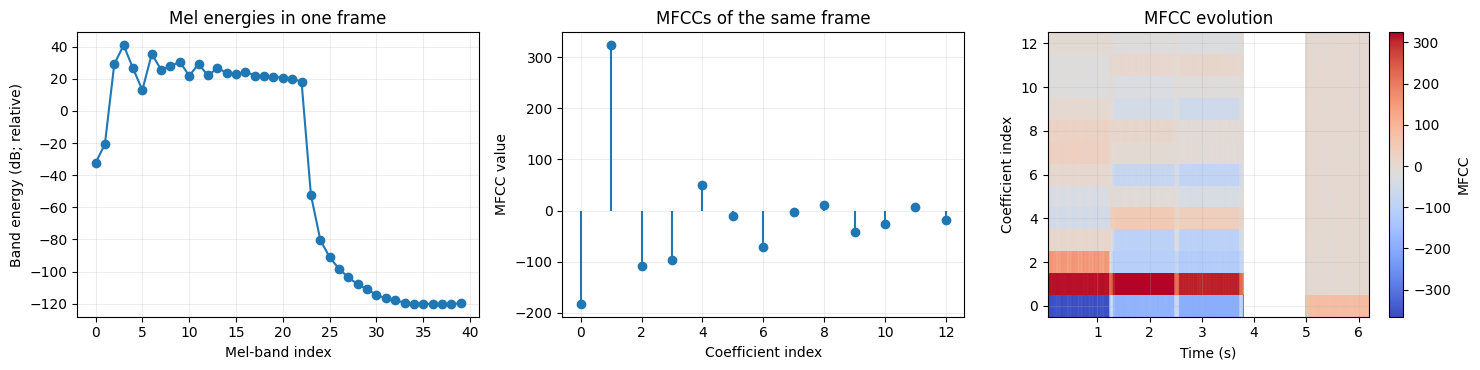

In [6]:
mfcc_alg = es.MFCC(inputSize=spectra.shape[1], sampleRate=SR,
                   highFrequencyBound=11000, numberBands=40,
                   numberCoefficients=13, type='power', logType='dbpow')
mel_bands = []
mfccs = []
for s in spectra:
    bands, coefficients = mfcc_alg(s)
    mel_bands.append(bands)
    mfccs.append(coefficients)
mel_bands = np.asarray(mel_bands)
mfccs = np.asarray(mfccs)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].plot(np.arange(mel_bands.shape[1]), 10*np.log10(np.maximum(mel_bands[inspect_idx], EPS)), 'o-')
axes[0].set(xlabel='Mel-band index', ylabel='Band energy (dB; relative)', title='Mel energies in one frame')
axes[1].stem(np.arange(mfccs.shape[1]), mfccs[inspect_idx], basefmt=' ')
axes[1].set(xlabel='Coefficient index', ylabel='MFCC value', title='MFCCs of the same frame')
mfcc_for_plot = mfccs.astype(float).copy()
# The log floor in silent frames produces arbitrary MFCCs; mask them for visualization.
mfcc_for_plot[rms < 1e-5] = np.nan
im = axes[2].imshow(np.ma.masked_invalid(mfcc_for_plot.T), origin='lower', aspect='auto', interpolation='nearest',
                    extent=(frame_times[0], frame_times[-1], -0.5, mfccs.shape[1]-0.5), cmap='coolwarm')
axes[2].set(xlabel='Time (s)', ylabel='Coefficient index', title='MFCC evolution')
fig.colorbar(im, ax=axes[2], label='MFCC')
plt.tight_layout()
plt.show()

## 5. Spectral peaks and the pitch salience function

A complex harmonic tone produces spectral peaks close to integer multiples of a **fundamental frequency** $f_0$:

$$
f_h\approx h f_0, \qquad h=1,2,3,\ldots
$$

A **pitch salience function** evaluates candidate fundamental frequencies: a candidate becomes more salient when multiple observed spectral peaks support its harmonic series. Schematically,

$$
S(f_0)\propto\sum_{h=1}^{H} w_h\;A(hf_0),
$$

where $A(hf_0)$ denotes the magnitude or energy associated with a peak near harmonic $h$, and $w_h$ is a decreasing harmonic weight. This is a *conceptual formula*, not the full Essentia implementation (which includes frequency quantization, magnitude weighting, and other details).

The procedure in the slides is **windowed spectrum → spectral peaks → pitch salience**. In Essentia use:

1. [`SpectralPeaks`](https://essentia.upf.edu/reference/std_SpectralPeaks.html), which returns arrays of *peak frequencies* and *peak magnitudes*.
2. [`PitchSalienceFunction`](https://essentia.upf.edu/reference/std_PitchSalienceFunction.html), which returns salience values sampled on a pitch grid with configurable resolution in **cents**.

We use 20-cent bins and a reference frequency of 55 Hz. Thus bin $j$ corresponds approximately to $f_j=55\,2^{20j/1200}$ Hz. A value of `max(salienceFunction)` is **not** a normalized confidence or an absolute perceptual measure, and the maximum can be affected by level and signal content.

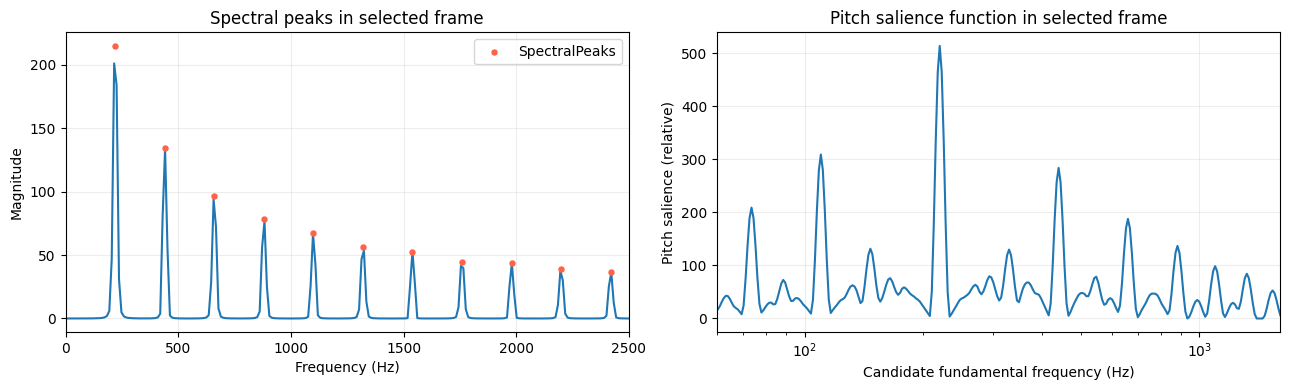

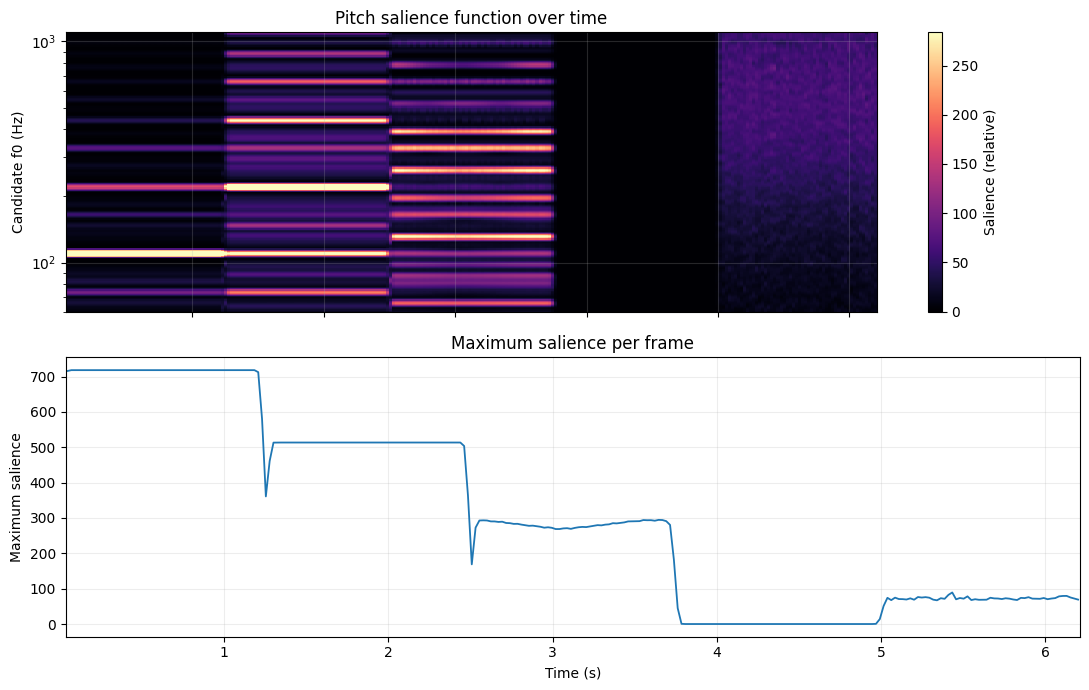

In [7]:
peak_alg = es.SpectralPeaks(sampleRate=SR, minFrequency=40, maxFrequency=5000,
                            maxPeaks=120, magnitudeThreshold=1e-6, orderBy='frequency')
peak_freqs, peak_mags = [], []
for s in spectra:
    f, m = peak_alg(s)
    peak_freqs.append(np.asarray(f))
    peak_mags.append(np.asarray(m))

PSF_CENTS = 20
PSF_REF = 55.0
salience_alg = es.PitchSalienceFunction(binResolution=PSF_CENTS,
                                       referenceFrequency=PSF_REF,
                                       numberHarmonics=20, harmonicWeight=0.8)
salience = np.asarray([salience_alg(f, m) for f, m in zip(peak_freqs, peak_mags)])
salience_freqs = PSF_REF * (2 ** (np.arange(salience.shape[1]) * PSF_CENTS / 1200.0))
max_salience = np.max(salience, axis=1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(freq_axis, spectra[inspect_idx])
axes[0].scatter(peak_freqs[inspect_idx], peak_mags[inspect_idx], s=13, color='tomato',
                label='SpectralPeaks', zorder=3)
axes[0].set(xlim=(0, 2500), xlabel='Frequency (Hz)', ylabel='Magnitude',
            title='Spectral peaks in selected frame')
axes[0].legend()
axes[1].plot(salience_freqs, salience[inspect_idx])
axes[1].set(xscale='log', xlim=(60, 1600), xlabel='Candidate fundamental frequency (Hz)',
            ylabel='Pitch salience (relative)', title='Pitch salience function in selected frame')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
colorscale = np.percentile(salience, 99) if np.any(salience > 0) else 1
im = axes[0].pcolormesh(frame_times, salience_freqs, salience.T, shading='auto',
                        cmap='magma', vmin=0, vmax=colorscale)
axes[0].set(yscale='log', ylim=(60, 1100), ylabel='Candidate f0 (Hz)',
            title='Pitch salience function over time')
fig.colorbar(im, ax=axes[0], label='Salience (relative)')
axes[1].plot(frame_times, max_salience, lw=1.3)
axes[1].set(xlabel='Time (s)', ylabel='Maximum salience', title='Maximum salience per frame')
plt.tight_layout()
plt.show()

### Optional comparison: Essentia's scalar `PitchSalience`

The scalar [`PitchSalience`](https://essentia.upf.edu/reference/std_PitchSalience.html) measures a peak in the **autocorrelation of the magnitude spectrum**, normalized by its zero-shift autocorrelation. It can be useful for characterizing percussive or tonal-vs-noisy sounds, but its scale and definition are **different** from the harmonic-summation function plotted above. **Do not** compare their numeric values as if they were the same descriptor.

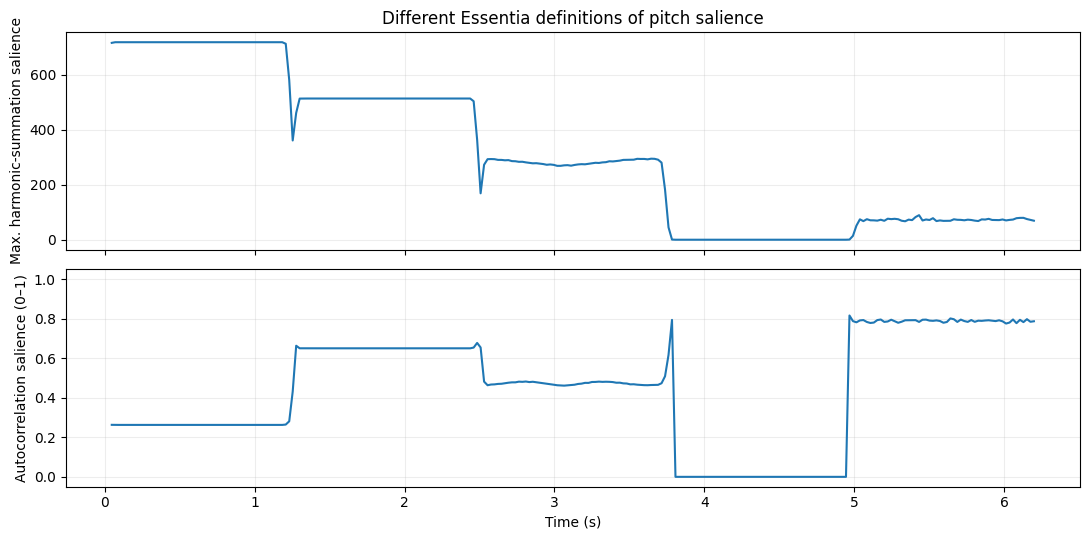

In [8]:
autocorr_salience_alg = es.PitchSalience(sampleRate=SR, lowBoundary=100, highBoundary=5000)
autocorr_salience = np.asarray([autocorr_salience_alg(s) for s in spectra])
fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
axes[0].plot(frame_times, max_salience)
axes[0].set(ylabel='Max. harmonic-summation salience', title='Different Essentia definitions of pitch salience')
axes[1].plot(frame_times, autocorr_salience)
axes[1].set(xlabel='Time (s)', ylabel='Autocorrelation salience (0–1)', ylim=(-0.05, 1.05))
plt.tight_layout()
plt.show()

## 6. Chroma / harmonic pitch class profile — HPCP

Western twelve-tone pitch classes *fold all octaves together*: A2 and A3 are in the same pitch class **A**. More generally, the pitch-class mapping for a frequency $f$ is related to

$$
p(f) = \big(12\log_2(f/f_{\mathrm{ref}})\big)\bmod 12.
$$

The **harmonic pitch class profile (HPCP)** assigns the spectral-peak contributions to the 12 pitch classes. Unlike a basic frequency-to-bin mapping, Essentia's HPCP supports frequency-dependent weighting, windowed contributions around pitch-class centers, tuning reference, and optional harmonic treatment.

Our configuration uses a 12-bin output, 440 Hz tuning reference, peak frequencies from 40 to 5000 Hz, and **unit-maximum normalization per frame**. This normalization is useful for inspecting pitch-class content, but **discards overall energy**: a weak and strong frame can have similarly shaped HPCPs. Silence should be handled explicitly, and noise may produce diffuse patterns.

**Essentia:** [`HPCP`](https://essentia.upf.edu/reference/std_HPCP.html), with the **same** `SpectralPeaks` outputs used for the salience function.

**Essentia's 12-bin order starts at A**, not C: `A, A#, B, C, C#, D, D#, E, F, F#, G, G#`. This is important when labeling a plot and interpreting chords.

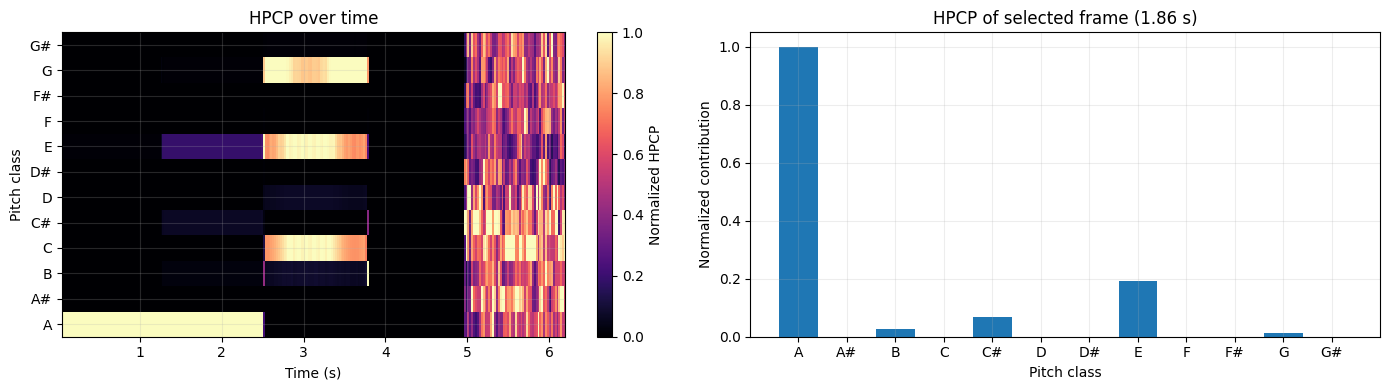

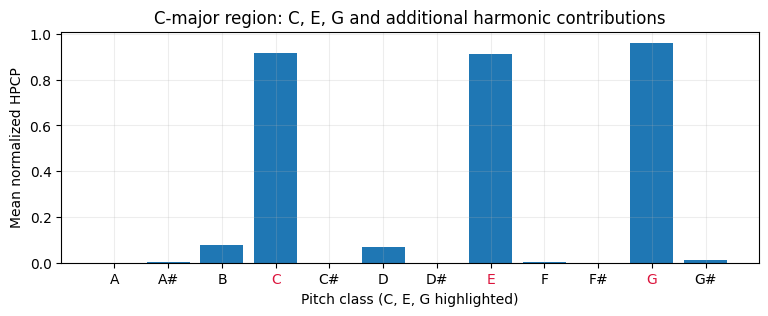

In [9]:
hpcp_alg = es.HPCP(size=12, sampleRate=SR, referenceFrequency=440,
                   minFrequency=40, maxFrequency=5000,
                   bandPreset=False, normalized='unitMax')
hpcp = np.asarray([hpcp_alg(f, m) if len(f) else np.zeros(12, dtype=np.float32)
                   for f, m in zip(peak_freqs, peak_mags)])
pitch_classes = ['A', 'A#', 'B', 'C', 'C#', 'D', 'D#', 'E', 'F', 'F#', 'G', 'G#']

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
im = axes[0].imshow(hpcp.T, origin='lower', aspect='auto', interpolation='nearest',
                    extent=(frame_times[0], frame_times[-1], -0.5, 11.5),
                    vmin=0, vmax=1, cmap='magma')
axes[0].set_yticks(np.arange(12))
axes[0].set_yticklabels(pitch_classes)
axes[0].set(xlabel='Time (s)', ylabel='Pitch class', title='HPCP over time')
fig.colorbar(im, ax=axes[0], label='Normalized HPCP')
axes[1].bar(np.arange(12), hpcp[inspect_idx])
axes[1].set_xticks(np.arange(12))
axes[1].set_xticklabels(pitch_classes)
axes[1].set(xlabel='Pitch class', ylabel='Normalized contribution',
            title=f'HPCP of selected frame ({frame_times[inspect_idx]:.2f} s)', ylim=(0, 1.05))
plt.tight_layout()
plt.show()

if regions:
    # Aggregate the C-major region, where we expect clear C/E/G contributions.
    chord_start = regions[2][1]
    chord_end = chord_start + regions[2][2]
    chord_mask = (frame_times >= chord_start + 0.05) & (frame_times < chord_end - 0.05)
    chord_hpcp = np.mean(hpcp[chord_mask], axis=0)
    fig, ax = plt.subplots(figsize=(9, 3))
    ax.bar(pitch_classes, chord_hpcp)
    for name in ['C', 'E', 'G']:
        ax.get_xticklabels()[pitch_classes.index(name)].set_color('crimson')
    ax.set(xlabel='Pitch class (C, E, G highlighted)', ylabel='Mean normalized HPCP',
           title='C-major region: C, E, G and additional harmonic contributions')
    plt.show()

## 7. Interactive frame inspector

Each feature emphasizes something different:

- **RMS** measures the overall signal level.
- **Centroid** describes spectral brightness.
- **MFCCs** describe the smoothed spectral shape.
- **Pitch salience** highlights candidate fundamentals supported by harmonics.
- **HPCP** aggregates musical pitch classes across octaves.

The following visualization brings the descriptors of **one frame** together. Selecting a time displays the nearest analyzed frame, so temporal changes can be connected to the waveform and spectrum. With `ipywidgets`, the time is selected with a slider; otherwise `show_frame(2.8)` displays the frame nearest 2.8 seconds.

In [10]:
def show_frame(time_s=1.85):
    idx = int(np.argmin(np.abs(frame_times - time_s)))
    fig, ax = plt.subplots(2, 3, figsize=(15, 8))
    # Original waveform of the frame.
    ax[0, 0].plot(np.arange(FRAME_SIZE)/SR, frames[idx], lw=0.8)
    ax[0, 0].set(xlabel='Time within frame (s)', ylabel='Amplitude', title='Waveform')
    ax[0, 1].plot(freq_axis, 20*np.log10(np.maximum(spectra[idx], EPS)), lw=0.8)
    ax[0, 1].axvline(centroid[idx], color='crimson', ls='--',
                     label=f'Centroid {centroid[idx]:.0f} Hz')
    ax[0, 1].set(xlim=(0, 5000), xlabel='Frequency (Hz)', ylabel='Magnitude (dB)', title='Spectrum')
    ax[0, 1].legend(loc='best')
    ax[0, 2].plot(np.arange(40), 10*np.log10(np.maximum(mel_bands[idx], EPS)), marker='.')
    ax[0, 2].set(xlabel='Mel band', ylabel='Relative dB', title='Mel-band energies')
    ax[1, 0].stem(np.arange(mfccs.shape[1]), mfccs[idx], basefmt=' ')
    ax[1, 0].set(xlabel='MFCC coefficient', ylabel='Value', title='MFCCs')
    ax[1, 1].plot(salience_freqs, salience[idx])
    ax[1, 1].set(xscale='log', xlim=(60, 1600), xlabel='Candidate f0 (Hz)',
                 ylabel='Salience (relative)', title='Pitch salience function')
    ax[1, 2].bar(np.arange(12), hpcp[idx])
    ax[1, 2].set_xticks(np.arange(12))
    ax[1, 2].set_xticklabels(pitch_classes)
    ax[1, 2].set(xlabel='Pitch class', ylabel='Normalized value', title='HPCP', ylim=(0, 1.05))
    fig.suptitle(f't = {frame_times[idx]:.2f} s | RMS = {rms[idx]:.3f} | '
                 f'Centroid = {centroid[idx]:.0f} Hz', fontsize=13)
    plt.tight_layout()
    plt.show()

try:
    import ipywidgets as widgets
    from IPython.display import display as display_widget
    slider = widgets.FloatSlider(value=min(1.85, frame_times[-1]), min=float(frame_times[0]),
                                 max=float(frame_times[-1]), step=HOP_SIZE/SR,
                                 description='Time (s)', readout_format='.2f',
                                 continuous_update=False, layout=widgets.Layout(width='70%'))
    display_widget(widgets.interactive(show_frame, time_s=slider))
except ImportError:
    print('ipywidgets is not installed; showing a static frame. Call show_frame(time_s) again to explore.')
    show_frame(min(1.85, frame_times[-1]))

interactive(children=(FloatSlider(value=1.85, continuous_update=False, description='Time (s)', layout=Layout(w…

## 8. From frames to sound descriptions: aggregation

A single frame provides only a local snapshot. Describing longer sounds often requires **statistics of a feature trajectory**. Examples from the slides:

- **Mean:** $\mu=\frac{1}{M}\sum_{m=1}^M f_m$.
- **Variance:** $\sigma^2=\frac{1}{M}\sum_{m=1}^M(f_m-\mu)^2$.
- **Skewness:** $\frac{1}{M}\sum_{m=1}^M (\frac{f_m-\mu}{\sigma})^3$ (when $\sigma>0$).

But an average **loses time order**. Two recordings can have the same average centroid and RMS but completely different temporal organization. For pitch-sensitive descriptors it is usually more informative to compare **regions** (harmonic tones, chords, noise) instead of compressing the entire signal into one number.

In [11]:
def stats(values):
    values = np.asarray(values, dtype=float)
    mean = np.mean(values)
    std = np.std(values)
    skew = np.mean(((values - mean) / std)**3) if std > EPS else 0.0
    return mean, std, skew

print(f'{"Feature":<22}{"Mean":>13}{"Std":>13}{"Skewness":>13}')
for name, values in [('RMS', rms), ('Centroid (Hz)', centroid),
                     ('Max pitch salience', max_salience), ('MFCC #1', mfccs[:, 1])]:
    mu, sigma, sk = stats(values)
    print(f'{name:<22}{mu:>13.4f}{sigma:>13.4f}{sk:>13.4f}')

if regions:
    print('\nFeature means in each synthesized region (exclude 0.05 s at each edge):')
    print(f'{"Region":<13}{"RMS":>11}{"Centroid Hz":>16}{"Max salience":>16}')
    for name, start, dur in regions:
        mask = (frame_times >= start + 0.05) & (frame_times < start + dur - 0.05)
        print(f'{name:<13}{rms[mask].mean():>11.3f}{centroid[mask].mean():>16.0f}'
              f'{max_salience[mask].mean():>16.3f}')

Feature                        Mean          Std     Skewness
RMS                          0.1835       0.1285       0.2564
Centroid (Hz)             2645.8817    4249.0673       1.4503
Max pitch salience         313.7004     266.3636       0.2810
MFCC #1                    187.2771     151.8544      -0.4046

Feature means in each synthesized region (exclude 0.05 s at each edge):
Region               RMS     Centroid Hz    Max salience
A2 mellow          0.395             202         718.310
A3 bright          0.225             993         513.512
C major            0.190             780         282.886
Silence            0.000               0           0.000
Noise              0.113           11040          72.782


## 9. Worked comparisons: three different aspects of a sound

The descriptors provide **complementary information**. The next cell computes two controlled comparisons automatically; there are no additional parameters to choose for the example to work.

### 9.1 Changing amplitude without changing the sound's spectral shape

Consider a frame $x[n]$ and a quieter copy $y[n]=a\,x[n]$, with $a=0.5$. From their definitions:

$$
E_y=a^2E_x, \qquad \operatorname{RMS}_y=|a|\operatorname{RMS}_x.
$$

For the simple Essentia loudness approximation $L=E^{0.67}$:

$$
L_y=|a|^{1.34}L_x.
$$

In contrast, the spectral centroid should remain essentially unchanged under uniform amplitude scaling, because the multiplier cancels between its numerator and denominator. These relationships show how **level descriptors** differ from a **spectral-shape descriptor**.

### 9.2 Changing harmonic content without changing the fundamental

Next we synthesize two sounds at the **same fundamental frequency of 220 Hz**, but with different strengths of their higher harmonics. The brighter sound should have a larger spectral centroid even though both have the same fundamental and pitch class. This separates **brightness** from **pitch**.

The original A2 and A3 segments additionally illustrate octave equivalence in the HPCP: both contain the pitch class A even though they have different fundamentals. Their full HPCP patterns need not be identical, because different harmonics also contribute to other pitch classes.

9.1  Amplitude scaling (a = 0.5)
Descriptor             Original      Quieter        Ratio
Energy                    204.4         51.1        0.250
RMS                      0.2234       0.1117        0.500
Loudness                  35.32        13.95        0.395
Centroid (Hz)             993.5        993.5        1.000
Expected ratios: Energy=0.250, RMS=0.500, Loudness=0.395, Centroid≈1.000

9.2  Same fundamental (220 Hz), different harmonic distribution
Mellow centroid: 434 Hz
Bright centroid: 1054 Hz


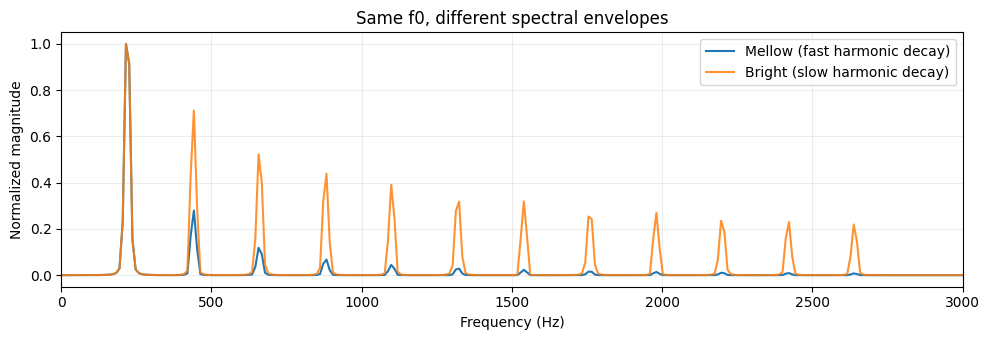

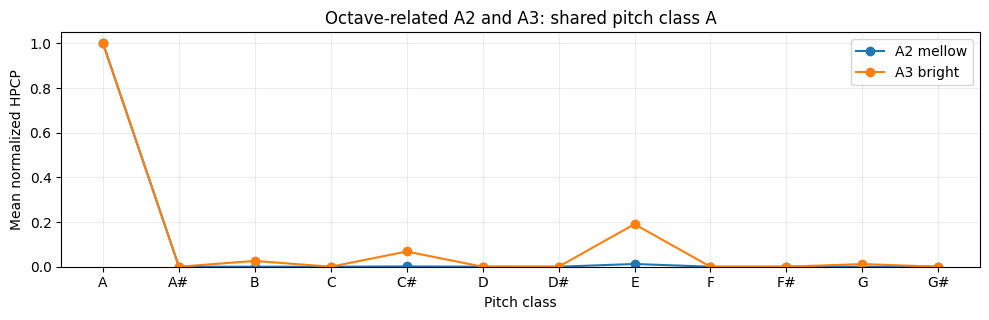

In [12]:
# Worked comparison 1: multiply the SAME frame by a fixed amplitude factor.
# Quantitative consequences are displayed directly for two frames.
reference_frame = frames[inspect_idx].astype(np.float32)
scale = 0.5
quieter_frame = scale * reference_frame


def frame_descriptor_summary(frame):
    spectrum = spectrum_alg(window(frame))
    return {
        'Energy': float(energy_alg(frame)),
        'RMS': float(rms_alg(frame)),
        'Loudness': float(loudness_alg(frame)),
        'Centroid (Hz)': float(centroid_alg(spectrum)) if spectrum.sum() > EPS else 0.0,
    }


before = frame_descriptor_summary(reference_frame)
after = frame_descriptor_summary(quieter_frame)
print('9.1  Amplitude scaling (a = 0.5)')
print(f'{"Descriptor":<18}{"Original":>13}{"Quieter":>13}{"Ratio":>13}')
for name in before:
    ratio = after[name] / before[name] if abs(before[name]) > EPS else float('nan')
    print(f'{name:<18}{before[name]:>13.4g}{after[name]:>13.4g}{ratio:>13.3f}')
print(f'Expected ratios: Energy={scale**2:.3f}, RMS={scale:.3f}, '
      f'Loudness={scale**1.34:.3f}, Centroid≈1.000')

# Worked comparison 2: retain the fundamental, modify only the harmonic decay.
# Both sounds are normalized to the same peak before their center frames are analyzed.
same_f0 = 220.0
mellow_220 = harmonic_tone(same_f0, 0.5, 1 / np.arange(1, 13)**2.0)
bright_220 = harmonic_tone(same_f0, 0.5, 1 / np.arange(1, 13)**0.65)


def center_frame(y):
    start = (len(y) - FRAME_SIZE) // 2
    return np.asarray(y[start:start + FRAME_SIZE], dtype=np.float32)


mellow_spectrum = spectrum_alg(window(center_frame(mellow_220)))
bright_spectrum = spectrum_alg(window(center_frame(bright_220)))
centroid_mellow = centroid_alg(mellow_spectrum)
centroid_bright = centroid_alg(bright_spectrum)

print('\n9.2  Same fundamental (220 Hz), different harmonic distribution')
print(f'Mellow centroid: {centroid_mellow:.0f} Hz')
print(f'Bright centroid: {centroid_bright:.0f} Hz')

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(freq_axis, mellow_spectrum / max(mellow_spectrum.max(), EPS), label='Mellow (fast harmonic decay)')
ax.plot(freq_axis, bright_spectrum / max(bright_spectrum.max(), EPS), label='Bright (slow harmonic decay)', alpha=0.85)
ax.set(xlim=(0, 3000), xlabel='Frequency (Hz)', ylabel='Normalized magnitude',
       title='Same f0, different spectral envelopes')
ax.legend()
plt.tight_layout()
plt.show()

# Octave comparison of mean HPCP values from the synthesized A2 and A3 regions.
if regions:
    fig, ax = plt.subplots(figsize=(10, 3.3))
    for region_index in (0, 1):
        name, start, duration = regions[region_index]
        mask = (frame_times >= start + 0.10) & (frame_times < start + duration - 0.10)
        if np.any(mask):
            ax.plot(pitch_classes, hpcp[mask].mean(axis=0), 'o-', label=name)
    ax.set(xlabel='Pitch class', ylabel='Mean normalized HPCP', ylim=(0, 1.05),
           title='Octave-related A2 and A3: shared pitch class A')
    ax.legend()
    plt.tight_layout()
    plt.show()


### Interpreting the demonstrations

The amplitude comparison gives predictable ratios because energy and RMS are directly defined from sample magnitudes. It also shows why **loudness, as implemented in this particular algorithm, is not the same quantity as either energy or RMS**. The two 220 Hz tones demonstrate that a change in harmonic balance can raise the centroid without changing the fundamental frequency. The HPCP comparison illustrates how pitch classes can remain related across octaves while the relative contribution of other classes changes.

### Consistency checks

The following checks verify array dimensions and finite numeric results. They are programmatic checks of the demonstration code, not tests of perceptual correctness.

In [13]:
assert len(frame_times) == len(frames) == len(spectra)
for name, data in {'energy': energy, 'rms': rms, 'loudness': loudness,
                   'centroid': centroid, 'mfccs': mfccs, 'hpcp': hpcp,
                   'salience': salience}.items():
    assert data.shape[0] == len(frames), (name, data.shape)
    assert np.all(np.isfinite(data)), f'{name} has non-finite values'
assert mfccs.shape[1] == 13
assert hpcp.shape[1] == 12
assert np.all(energy >= 0) and np.all(rms >= 0)
print('All feature arrays have the expected dimensions and finite values.')

All feature arrays have the expected dimensions and finite values.


## 10. References and further exploration

**Essentia documentation:**

- [Algorithms reference](https://essentia.upf.edu/algorithms_reference.html) — all algorithms, parameters, and output specifications.
- [Energy](https://essentia.upf.edu/reference/std_Energy.html), [RMS](https://essentia.upf.edu/reference/std_RMS.html), [Loudness](https://essentia.upf.edu/reference/std_Loudness.html), [LoudnessEBUR128](https://essentia.upf.edu/reference/std_LoudnessEBUR128.html).
- [Centroid](https://essentia.upf.edu/reference/std_Centroid.html), [MFCC](https://essentia.upf.edu/reference/std_MFCC.html).
- [SpectralPeaks](https://essentia.upf.edu/reference/std_SpectralPeaks.html), [PitchSalienceFunction](https://essentia.upf.edu/reference/std_PitchSalienceFunction.html), [PitchSalience](https://essentia.upf.edu/reference/std_PitchSalience.html), [HPCP](https://essentia.upf.edu/reference/std_HPCP.html).
- [Essentia Python examples](https://essentia.upf.edu/python_examples.html).
- [sms-tools-materials examples](https://github.com/MTG/sms-tools-materials/tree/main/examples).

**Teaching note:** Because the algorithms differ in normalization and input interpretation, keep the analysis parameters (sample rate, frame size, hop, windowing, reference tuning, mel settings, frequency ranges) documented when comparing results across sounds or libraries. The formulas in the notebook convey the main concepts; algorithm-specific details are defined by Essentia's reference pages.